In [1]:
import json
import math
import os

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils

import ignite
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore

In [2]:
DATA_DIR = "chest_xray/train"
OUT_DIR = "outputs"
IMG_SIZE = 128
LATENT_DIM = 128
BATCH_SIZE = 64
EPOCHS = 80
LR = 1e-3
BETA = 1.0
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_size=IMG_SIZE):
        super().__init__()
        assert img_size >= 8 and (img_size & (img_size - 1)) == 0, "Error: IMG_SIZE"
        n_layers = int(math.log2(img_size // 4))
        chs = [1] + [min(32 * 2 ** i, 512) for i in range(n_layers)]

        # Encoder: 1 x img x img -> chs[-1] x 4 x 4
        enc = []
        for c_in, c_out in zip(chs[:-1], chs[1:]):
            enc += [nn.Conv2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2)]
        self.encoder = nn.Sequential(*enc, nn.Flatten())

        feat_dim = chs[-1] * 4 * 4
        self.fc_mu = nn.Linear(feat_dim, latent_dim)
        self.fc_logvar = nn.Linear(feat_dim, latent_dim)

        # Decoder: latent -> 1 x img x img
        self.fc_dec = nn.Linear(latent_dim, feat_dim)
        rev = chs[::-1]
        dec = [nn.Unflatten(1, (chs[-1], 4, 4))]
        for c_in, c_out in zip(rev[:-2], rev[1:-1]):
            dec += [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.ReLU()]
        dec += [nn.ConvTranspose2d(rev[-2], 1, 4, 2, 1), nn.Sigmoid()]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(self.fc_dec(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [4]:
def vae_loss(recon, x, mu, logvar, beta=BETA):
    recon_loss = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + beta * kl, recon_loss, kl

In [5]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
])
dataset = datasets.ImageFolder(DATA_DIR, transform=transform)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=2, drop_last=True)

In [6]:
model = VAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {"total": [], "recon": [], "kl": []}
fixed_z = torch.randn(64, LATENT_DIM, device=device)

for epoch in range(1, EPOCHS + 1):
    model.train()
    sums = {"total": 0.0, "recon": 0.0, "kl": 0.0}
    for x, _ in loader:
        x = x.to(device)
        recon, mu, logvar = model(x)
        loss, rl, kl = vae_loss(recon, x, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        sums["total"] += loss.item()
        sums["recon"] += rl.item()
        sums["kl"] += kl.item()

    for k in sums:
        history[k].append(sums[k] / len(loader))
    print(f"Epoch {epoch:3d} | loss {history['total'][-1]:.2f} "
          f"| recon {history['recon'][-1]:.2f} | KL {history['kl'][-1]:.2f}")

    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            samples = model.decode(fixed_z)
        utils.save_image(samples, f"{OUT_DIR}/samples_epoch{epoch}.png", nrow=8)

torch.save(model.state_dict(), f"{OUT_DIR}/vae.pt")
with open(f"{OUT_DIR}/loss_history.json", "w") as f:
    json.dump(history, f)

Epoch   1 | loss 10920.29 | recon 10746.26 | KL 174.03
Epoch   2 | loss 10498.65 | recon 10419.32 | KL 79.33
Epoch   3 | loss 10421.93 | recon 10351.07 | KL 70.86
Epoch   4 | loss 10376.16 | recon 10313.74 | KL 62.42
Epoch   5 | loss 10350.11 | recon 10292.26 | KL 57.85
Epoch   6 | loss 10334.45 | recon 10279.52 | KL 54.93
Epoch   7 | loss 10324.66 | recon 10271.37 | KL 53.29
Epoch   8 | loss 10317.64 | recon 10265.63 | KL 52.00
Epoch   9 | loss 10311.04 | recon 10260.04 | KL 51.01
Epoch  10 | loss 10306.91 | recon 10255.74 | KL 51.17
Epoch  11 | loss 10300.71 | recon 10250.66 | KL 50.06
Epoch  12 | loss 10297.42 | recon 10248.33 | KL 49.09
Epoch  13 | loss 10296.27 | recon 10246.89 | KL 49.38
Epoch  14 | loss 10292.21 | recon 10243.67 | KL 48.54
Epoch  15 | loss 10290.95 | recon 10241.92 | KL 49.03
Epoch  16 | loss 10291.80 | recon 10243.17 | KL 48.63
Epoch  17 | loss 10289.54 | recon 10241.23 | KL 48.31
Epoch  18 | loss 10286.43 | recon 10238.38 | KL 48.05
Epoch  19 | loss 10285.31 |

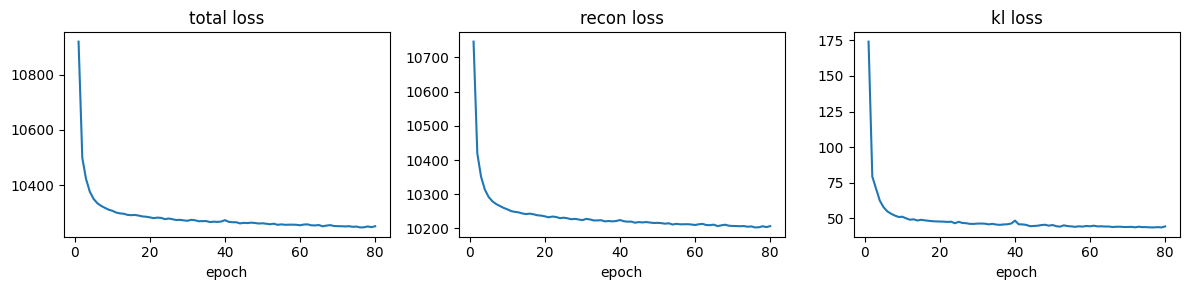

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, key in zip(axes, ["total", "recon", "kl"]):
    ax.plot(range(1, EPOCHS + 1), history[key])
    ax.set_title(f"{key} loss")
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves.png", dpi=150)

@torch.no_grad()
def generate(model, n):
    model.eval()
    z = torch.randn(n, LATENT_DIM, device=device)
    return model.decode(z)

utils.save_image(generate(model, 64), f"{OUT_DIR}/final_samples.png", nrow=8)

In [8]:
def prepare_inception(batch):
    images = []
    for image in batch.detach().cpu():
        image = to_pil(image).convert("RGB")
        image = image.resize(
            (299, 299),
            resample=Image.Resampling.BILINEAR,
        )
        images.append(to_tensor(image))

    return torch.stack(images).to(eval_device)

In [9]:
model.eval()
eval_device = next(model.parameters()).device
latent_dim = model.fc_mu.out_features
eval_seed = 342
rng = torch.Generator(device=eval_device).manual_seed(eval_seed)

with torch.no_grad():
    probe = model.decode(
        torch.zeros(1, latent_dim, device=eval_device)
    )
eval_size = probe.shape[-1]

In [10]:
test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(eval_size),
    transforms.CenterCrop(eval_size),
    transforms.ToTensor(),
])

to_pil = transforms.ToPILImage()
to_tensor = transforms.ToTensor()

test_dataset = datasets.ImageFolder(
    "chest_xray/test",
    transform=test_transform,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

In [11]:
@torch.no_grad()
def evaluation_step(engine, batch):
    real = batch[0]
    z = torch.randn(
        real.size(0),
        latent_dim,
        generator=rng,
        device=eval_device,
    )
    fake = model.decode(z)

    return prepare_inception(fake), prepare_inception(real)


evaluator = Engine(evaluation_step)

FID(device=eval_device).attach(evaluator, "fid")

InceptionScore(
    device=eval_device,
    output_transform=lambda output: output[0],
).attach(evaluator, "is")

metrics = evaluator.run(test_loader).metrics


In [ ]:
results = {
    "fid": float(metrics["fid"]),
    "inception_score": float(metrics["is"]),
    "n_real": len(test_dataset),
    "n_generated": len(test_dataset),
    "image_size": eval_size,
    "latent_dim": latent_dim,
    "seed": eval_seed,
    "ignite_version": ignite.__version__,
    "preprocessing": (
        "grayscale, Resize + CenterCrop, [0,1], "
        "PIL RGB bilinear resize to 299x299"
    ),
    "metric_implementation": "Ignite default Inception, 1000 dimensions",
}

save_dir = Path("outputs")
save_dir.mkdir(parents=True, exist_ok=True)

with open(save_dir / f"metrics_{eval_size}.json", "w") as f:
    json.dump(results, f, indent=2)

print(f"FID: {results['fid']:.6f}")
print(f"Inception Score: {results['inception_score']:.6f}")
print("Real/generated images:", len(test_dataset))

FID: 0.152624
Inception Score: 1.670664
Real/generated images: 624
